# Aula 2 — Physics-Informed Machine Learning
## PINN para escoamento potencial 2D em torno de um cilindro

Na Aula 1 o surrogate aprendeu **só com dados**: $\mathbf{x} \rightarrow y$. Aqui a rede aprende um
**campo físico inteiro** a partir da **equação** que o governa — sem nenhum dado rotulado dentro do domínio.

**Problema:** escoamento potencial (invíscido, incompressível, irrotacional) em torno de um cilindro de
raio $a$ — uma representação simplificada da seção de um membro offshore (coluna, riser, pontoon).

$$
\nabla^2 \phi = 0 \quad \text{em } a < r < R_\infty, \qquad
\frac{\partial \phi}{\partial n}\Big|_{r=a} = 0 \ \text{(impermeabilidade)}, \qquad
\phi\big|_{r=R_\infty} = U_\infty\, x \ \text{(escoamento uniforme)}
$$

**Validação** contra a solução analítica: potencial $\phi$, campo de velocidade $\mathbf{u} = \nabla\phi$,

## 1. Imports e configuração

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

torch.manual_seed(0)
np.random.seed(0)
print("PyTorch:", torch.__version__)


PyTorch: 2.11.0+cpu


In [2]:
# ---- parâmetros físicos ----
U_INF = 1.0      # velocidade do escoamento livre
A = 1.0          # raio do cilindro
R_OUT = 5.0      # raio do contorno externo (domínio computacional truncado)

# Condição no contorno externo:
#   "uniform" -> phi = U x  (condição física: só sabemos que longe do corpo o escoamento é uniforme)
#   "exact"   -> phi = solução analítica de domínio infinito (remove o efeito de truncamento do domínio)
FARFIELD_BC = "uniform"

# ---- parâmetros de treino ----
N_COL = 3000      # pontos de colocação no interior (onde a EDP é imposta)
N_BC = 200        # pontos em cada contorno
N_ADAM = 3000     # iterações de Adam
N_LBFGS = 1000    # iterações máximas de L-BFGS (refinamento final)


## 2. Solução analítica de referência

Para o domínio infinito, a solução clássica (escoamento uniforme + dipolo) é

$$
\phi(r,\theta) = U_\infty\left(r + \frac{a^2}{r}\right)\cos\theta,
\qquad u_\theta\big|_{r=a} = -2U_\infty\sin\theta,
\qquad C_p(\theta) = 1 - 4\sin^2\theta .
$$

Como o domínio computacional é **truncado** em $r = R_\infty$, com $\phi = U_\infty x$ imposto ali, a
solução exata do problema que realmente resolvemos é a mesma forma multiplicada por um fator
$\kappa = R_\infty^2/(R_\infty^2 + a^2)$ (para $R_\infty = 5$, $\kappa \approx 0{,}96$):

$$
\phi_{\text{trunc}} = \kappa\, U_\infty\left(r + \frac{a^2}{r}\right)\cos\theta,
\qquad C_{p,\text{trunc}}(\theta) = 1 - 4\kappa^2\sin^2\theta .
$$

A PINN deve reproduzir $\phi_{\text{trunc}}$. A diferença entre $\phi_{\text{trunc}}$ e a solução infinita
é **erro de modelagem do domínio** — o mesmo que aparece em CFD quando o contorno externo fica perto
demais do corpo —, não erro de aprendizado da rede.


In [3]:
KAPPA = R_OUT**2 / (R_OUT**2 + A**2) if FARFIELD_BC == "uniform" else 1.0
print(f"kappa = {KAPPA:.4f}")

def phi_ref(x, y, kappa=KAPPA):
    r2 = x**2 + y**2
    return kappa * U_INF * x * (1 + A**2 / r2)

def vel_ref(x, y, kappa=KAPPA):
    r4 = (x**2 + y**2) ** 2
    u = kappa * U_INF * (1 - A**2 * (x**2 - y**2) / r4)
    v = -kappa * U_INF * 2 * A**2 * x * y / r4
    return u, v

def cp_ref(theta, kappa=KAPPA):
    return 1 - 4 * kappa**2 * np.sin(theta) ** 2


kappa = 0.9615


## 3. A peça-chave: diferenciação automática

A PINN precisa de $\partial^2\phi/\partial x^2$ e $\partial^2\phi/\partial y^2$ da **própria rede**. O
`torch.autograd` calcula essas derivadas **exatamente** (regra da cadeia aplicada ao grafo computacional),
sem diferenças finitas e sem malha. Teste rápido com $f(x) = \sin x$:


In [4]:
x = torch.linspace(0, 2 * np.pi, 6, requires_grad=True)
f = torch.sin(x)

df = torch.autograd.grad(f, x, torch.ones_like(f), create_graph=True)[0]      # f'  = cos x
d2f = torch.autograd.grad(df, x, torch.ones_like(df))[0]                      # f'' = -sin x

print("f'  (autograd):", np.round(df.detach().numpy(), 4))
print("cos x        :", np.round(np.cos(x.detach().numpy()), 4))
print("f'' (autograd):", np.round(d2f.numpy(), 4))
print("-sin x       :", np.round(-np.sin(x.detach().numpy()), 4))


f'  (autograd): [ 1.     0.309 -0.809 -0.809  0.309  1.   ]
cos x        : [ 1.     0.309 -0.809 -0.809  0.309  1.   ]
f'' (autograd): [-0.     -0.9511 -0.5878  0.5878  0.9511 -0.    ]
-sin x       : [-0.     -0.9511 -0.5878  0.5878  0.9511 -0.    ]


In [5]:
def grad(out, inp):
    # derivada de 'out' em relação a 'inp', mantendo o grafo para derivar de novo
    return torch.autograd.grad(out, inp, torch.ones_like(out), create_graph=True)[0]

def laplacian(phi, xy):
    g = grad(phi, xy)
    phi_xx = grad(g[:, 0:1], xy)[:, 0:1]
    phi_yy = grad(g[:, 1:2], xy)[:, 1:2]
    return phi_xx + phi_yy


## 4. Pontos de colocação e pontos de contorno

A PINN não usa malha nem dados rotulados no interior. Usa três conjuntos de pontos:

- **colocação** (interior): onde se exige $\nabla^2\phi = 0$ — sem rótulo, só a equação;
- **superfície do cilindro**: onde se exige $\partial\phi/\partial n = 0$;
- **contorno externo**: onde se impõe o escoamento uniforme.

Os pontos de colocação são amostrados com densidade maior perto do cilindro (uniforme em $\log r$),
onde o campo varia mais.


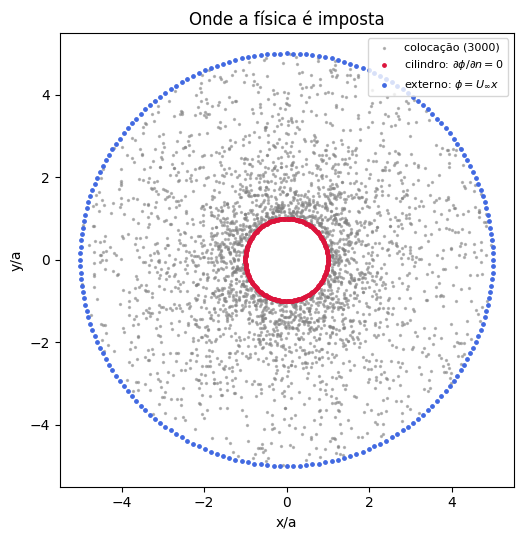

In [6]:
def sample_interior(n):
    r = A * (R_OUT / A) ** np.random.rand(n)          # log-uniforme em r
    th = 2 * np.pi * np.random.rand(n)
    return np.stack([r * np.cos(th), r * np.sin(th)], axis=1)

def ring(n, r):
    th = np.linspace(0, 2 * np.pi, n, endpoint=False)
    return np.stack([r * np.cos(th), r * np.sin(th)], axis=1), th

xy_col_np = sample_interior(N_COL)
xy_cyl_np, th_cyl = ring(N_BC, A)
xy_far_np, _ = ring(N_BC, R_OUT)

if FARFIELD_BC == "uniform":
    phi_far_np = U_INF * xy_far_np[:, 0:1]
else:
    phi_far_np = phi_ref(xy_far_np[:, 0], xy_far_np[:, 1], kappa=1.0)[:, None]

to_t = lambda a, g=False: torch.tensor(a, dtype=torch.float32, requires_grad=g)
xy_col = to_t(xy_col_np, True)
xy_cyl = to_t(xy_cyl_np, True)
xy_far = to_t(xy_far_np)
phi_far = to_t(phi_far_np)
n_cyl = to_t(xy_cyl_np / A)        # normal unitária na superfície do cilindro

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(xy_col_np[:, 0], xy_col_np[:, 1], s=2, c="gray", alpha=0.5, label=f"colocação ({N_COL})")
ax.scatter(xy_cyl_np[:, 0], xy_cyl_np[:, 1], s=6, c="crimson", label=r"cilindro: $\partial\phi/\partial n=0$")
ax.scatter(xy_far_np[:, 0], xy_far_np[:, 1], s=6, c="royalblue", label=r"externo: $\phi=U_\infty x$")
ax.set_aspect("equal"); ax.set_xlabel("x/a"); ax.set_ylabel("y/a")
ax.set_title("Onde a física é imposta")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.show()


## 5. A rede e a perda física

A rede recebe coordenadas $(x, y)$ e devolve $\phi(x, y)$ — é uma MLP igual à da Aula 1; o que muda é a
**função de perda**:

$$
\mathcal{L} = \underbrace{\frac{1}{N_c}\sum \big(\nabla^2\phi\big)^2}_{\text{resíduo da EDP}}
+ \underbrace{\frac{1}{N_b}\sum \Big(\frac{\partial\phi}{\partial n}\Big)^2_{r=a}}_{\text{impermeabilidade}}
+ \underbrace{\frac{1}{N_b}\sum \big(\phi - U_\infty x\big)^2_{r=R_\infty}}_{\text{escoamento livre}}
$$

Nenhum termo usa a solução analítica. As entradas são divididas por $R_\infty$ e a saída multiplicada por
$R_\infty$, para a rede trabalhar com valores de ordem 1.


In [7]:
class PINN(nn.Module):
    def __init__(self, width=40, depth=4):
        super().__init__()
        layers, n_in = [], 2
        for _ in range(depth):
            layers += [nn.Linear(n_in, width), nn.Tanh()]   # tanh: suave, derivadas de 2a ordem não nulas
            n_in = width
        layers += [nn.Linear(n_in, 1)]
        self.net = nn.Sequential(*layers)

    def forward(self, xy):
        return R_OUT * self.net(xy / R_OUT)

def pinn_losses(model):
    l_pde = (laplacian(model(xy_col), xy_col) ** 2).mean()
    dphi_dn = (grad(model(xy_cyl), xy_cyl) * n_cyl).sum(dim=1)
    l_cyl = (dphi_dn ** 2).mean()
    l_far = ((model(xy_far) - phi_far) ** 2).mean() / R_OUT**2
    return l_pde, l_cyl, l_far

model = PINN()
print(model)
print("Número de parâmetros:", sum(p.numel() for p in model.parameters()))


PINN(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=40, bias=True)
    (1): Tanh()
    (2): Linear(in_features=40, out_features=40, bias=True)
    (3): Tanh()
    (4): Linear(in_features=40, out_features=40, bias=True)
    (5): Tanh()
    (6): Linear(in_features=40, out_features=40, bias=True)
    (7): Tanh()
    (8): Linear(in_features=40, out_features=1, bias=True)
  )
)
Número de parâmetros: 5081


## 6. Treinamento: Adam + L-BFGS

Estratégia usual em PINNs: **Adam** para sair da inicialização aleatória e **L-BFGS** (quasi-Newton) para
refinar. O L-BFGS é o mesmo tipo de método de otimização visto na disciplina, aplicado aos pesos da rede.


In [8]:
history = {"total": [], "pde": [], "cyl": [], "far": []}

def log(lp, lc, lf):
    history["pde"].append(lp.item()); history["cyl"].append(lc.item()); history["far"].append(lf.item())
    history["total"].append((lp + lc + lf).item())

t0 = time.time()
adam = torch.optim.Adam(model.parameters(), lr=2e-3)
sched = torch.optim.lr_scheduler.StepLR(adam, step_size=1000, gamma=0.5)
for it in range(N_ADAM):
    adam.zero_grad()
    lp, lc, lf = pinn_losses(model)
    (lp + lc + lf).backward()
    adam.step(); sched.step()
    log(lp, lc, lf)
    if it % 500 == 0:
        print(f"Adam {it:5d} | perda = {history['total'][-1]:.2e}  (EDP {lp.item():.1e}, cilindro {lc.item():.1e}, externo {lf.item():.1e})")
n_adam_logged = len(history["total"])

lbfgs = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=N_LBFGS, history_size=50,
                          tolerance_grad=1e-9, tolerance_change=1e-12, line_search_fn="strong_wolfe")
def closure():
    lbfgs.zero_grad()
    lp, lc, lf = pinn_losses(model)
    loss = lp + lc + lf
    loss.backward()
    log(lp, lc, lf)
    return loss
lbfgs.step(closure)

print(f"L-BFGS    | perda final = {history['total'][-1]:.2e}")
print(f"Tempo total de treino: {time.time() - t0:.0f} s")


Adam     0 | perda = 4.69e-01  (EDP 2.7e-05, cilindro 2.2e-03, externo 4.7e-01)
Adam   500 | perda = 1.49e-01  (EDP 6.0e-02, cilindro 4.4e-02, externo 4.4e-02)
Adam  1000 | perda = 7.22e-02  (EDP 4.1e-02, cilindro 1.8e-02, externo 1.4e-02)
Adam  1500 | perda = 7.91e-04  (EDP 7.5e-04, cilindro 2.5e-05, externo 1.9e-05)
Adam  2000 | perda = 3.24e-04  (EDP 3.1e-04, cilindro 6.8e-06, externo 9.2e-06)
Adam  2500 | perda = 2.40e-04  (EDP 2.3e-04, cilindro 4.4e-06, externo 7.2e-06)
L-BFGS    | perda final = 1.05e-05
Tempo total de treino: 170 s


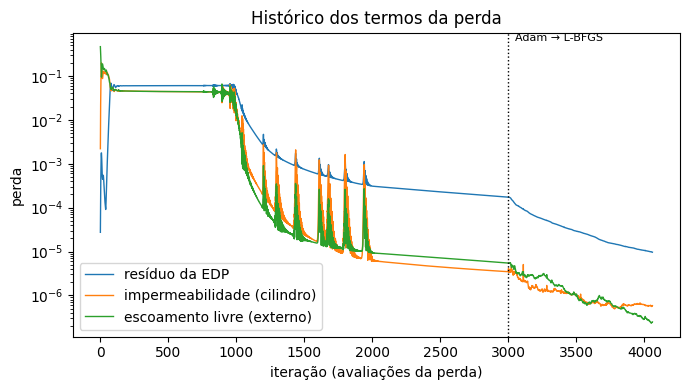

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
for key, lab in [("pde", "resíduo da EDP"), ("cyl", "impermeabilidade (cilindro)"), ("far", "escoamento livre (externo)")]:
    ax.semilogy(history[key], label=lab, lw=1)
ax.axvline(n_adam_logged, color="k", ls=":", lw=1)
ax.text(n_adam_logged, ax.get_ylim()[1], "  Adam → L-BFGS", va="top", fontsize=8)
ax.set_xlabel("iteração (avaliações da perda)"); ax.set_ylabel("perda")
ax.set_title("Histórico dos termos da perda")
ax.legend(); plt.tight_layout(); plt.show()


## 7. Validação — potencial e campo de velocidade

A velocidade vem de $\mathbf{u} = \nabla\phi$, calculada também por autograd sobre a rede treinada.


Erro relativo L2 do potencial phi   : 0.045 %
Erro relativo L2 da velocidade u, v : 0.210 %


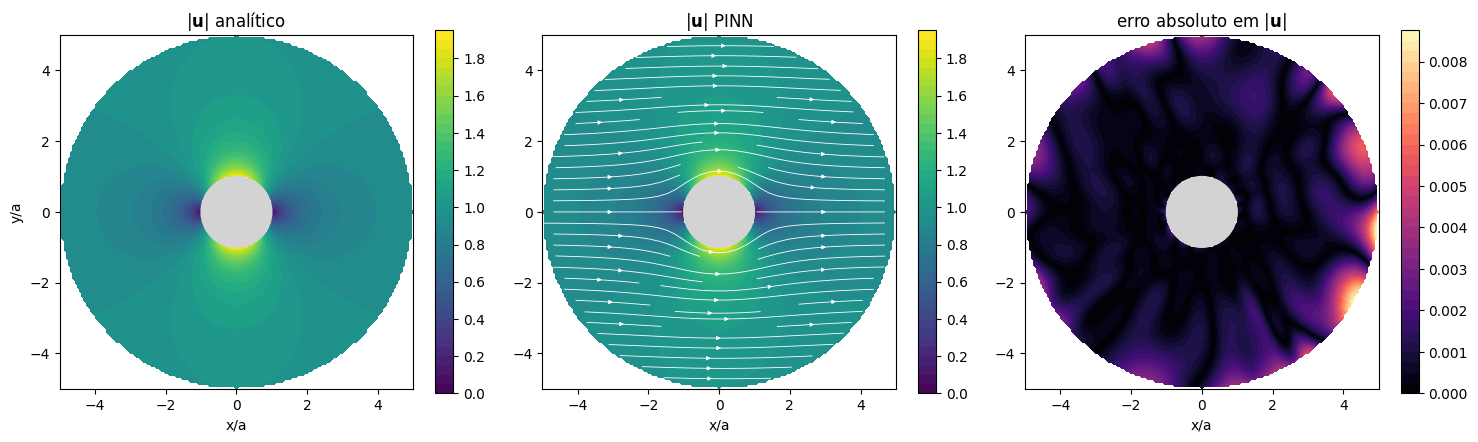

In [10]:
def pinn_velocity(model, xy_np):
    xy = to_t(xy_np, True)
    phi = model(xy)
    g = torch.autograd.grad(phi, xy, torch.ones_like(phi))[0]
    return phi.detach().numpy().ravel(), g[:, 0].detach().numpy(), g[:, 1].detach().numpy()

# malha cartesiana só para visualização (a PINN não precisa dela)
n_grid = 161
gx, gy = np.meshgrid(np.linspace(-R_OUT, R_OUT, n_grid), np.linspace(-R_OUT, R_OUT, n_grid))
gr = np.sqrt(gx**2 + gy**2)
inside = (gr >= A) & (gr <= R_OUT)
xy_grid = np.stack([gx[inside], gy[inside]], axis=1)

phi_p, u_p, v_p = pinn_velocity(model, xy_grid)
phi_e = phi_ref(xy_grid[:, 0], xy_grid[:, 1])
u_e, v_e = vel_ref(xy_grid[:, 0], xy_grid[:, 1])

err_phi = np.linalg.norm(phi_p - phi_e) / np.linalg.norm(phi_e)
err_vel = np.sqrt(np.sum((u_p - u_e)**2 + (v_p - v_e)**2) / np.sum(u_e**2 + v_e**2))
print(f"Erro relativo L2 do potencial phi   : {100*err_phi:.3f} %")
print(f"Erro relativo L2 da velocidade u, v : {100*err_vel:.3f} %")

def to_field(vals):
    F = np.full(gx.shape, np.nan); F[inside] = vals
    return np.ma.masked_invalid(F)

speed_p = to_field(np.hypot(u_p, v_p)); speed_e = to_field(np.hypot(u_e, v_e))
err_speed = to_field(np.abs(np.hypot(u_p, v_p) - np.hypot(u_e, v_e)))
U_p, V_p = to_field(u_p), to_field(v_p)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
vmax = float(speed_e.max())
for ax, F, title in [(axes[0], speed_e, r"$|\mathbf{u}|$ analítico"), (axes[1], speed_p, r"$|\mathbf{u}|$ PINN")]:
    im = ax.contourf(gx, gy, F, levels=40, cmap="viridis", vmin=0, vmax=vmax)
    ax.set_title(title); fig.colorbar(im, ax=ax, shrink=0.85)
axes[1].streamplot(gx, gy, U_p, V_p, color="w", density=1.1, linewidth=0.6, arrowsize=0.6)
im = axes[2].contourf(gx, gy, err_speed, levels=40, cmap="magma")
axes[2].set_title(r"erro absoluto em $|\mathbf{u}|$"); fig.colorbar(im, ax=axes[2], shrink=0.85)
for ax in axes:
    ax.add_patch(plt.Circle((0, 0), A, color="lightgray", zorder=5))
    ax.set_aspect("equal"); ax.set_xlabel("x/a")
axes[0].set_ylabel("y/a")
plt.tight_layout(); plt.show()


## 8. Por que a física importa: modelo só-dados × PINN

Contraste com a abordagem da Aula 1. Suponha que temos **medições** de $\phi$ em 60 pontos, todos na região
a montante do cilindro ($x < -2$) — como sensores posicionados só de um lado. Treinamos a **mesma**
arquitetura só com esses dados (perda MSE, sem física) e comparamos com a PINN, que não usou **nenhuma**
medição.


In [11]:
np.random.seed(1); torch.manual_seed(1)
pool = sample_interior(20000)
pool = pool[pool[:, 0] < -2.0]
xy_data_np = pool[np.random.choice(len(pool), 60, replace=False)]
phi_data = to_t(phi_ref(xy_data_np[:, 0], xy_data_np[:, 1])[:, None])
xy_data = to_t(xy_data_np)

model_data = PINN()   # mesma arquitetura, só muda a perda
opt_d = torch.optim.Adam(model_data.parameters(), lr=2e-3)
for it in range(3000):
    opt_d.zero_grad()
    loss_d = ((model_data(xy_data) - phi_data) ** 2).mean()
    loss_d.backward(); opt_d.step()
print(f"MSE final nos 60 pontos medidos: {loss_d.item():.2e}  (o modelo ajusta muito bem os dados...)")

phi_d, u_d, v_d = pinn_velocity(model_data, xy_grid)
err_vel_d = np.sqrt(np.sum((u_d - u_e)**2 + (v_d - v_e)**2) / np.sum(u_e**2 + v_e**2))
_, us_d, vs_d = pinn_velocity(model_data, xy_surf)
cp_data = 1 - (us_d**2 + vs_d**2) / U_INF**2
print(f"Erro relativo L2 da velocidade -- só dados: {100*err_vel_d:.1f} %   |   PINN: {100*err_vel:.2f} %")


MSE final nos 60 pontos medidos: 3.45e-04  (o modelo ajusta muito bem os dados...)


NameError: name 'xy_surf' is not defined

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1, 1.25]})
speed_d = to_field(np.hypot(u_d, v_d))
for ax, F, title in [(axes[0], speed_d, "só dados (60 medições, sem física)"), (axes[1], speed_p, "PINN (só física, sem medições)")]:
    im = ax.contourf(gx, gy, np.clip(F, 0, vmax), levels=40, cmap="viridis", vmin=0, vmax=vmax)
    ax.add_patch(plt.Circle((0, 0), A, color="lightgray", zorder=5))
    ax.set_aspect("equal"); ax.set_title(title); ax.set_xlabel("x/a")
axes[0].scatter(xy_data_np[:, 0], xy_data_np[:, 1], s=10, c="red", edgecolor="w", lw=0.4, label="medições")
axes[0].legend(loc="upper right", fontsize=8); axes[0].set_ylabel("y/a")
fig.colorbar(im, ax=axes[:2], shrink=0.85, label=r"$|\mathbf{u}|/U_\infty$")

axes[2].plot(deg, cp_ref(th_plot), "k", lw=2, label="analítico")
axes[2].plot(deg, cp_pinn, color="crimson", lw=1.5, ls="--", label="PINN")
axes[2].plot(deg, cp_data, color="darkorange", lw=1.5, label="só dados")
axes[2].set_xlabel(r"$\theta$ (graus)"); axes[2].set_ylabel(r"$C_p$"); axes[2].set_xticks(range(0, 361, 90))
axes[2].set_title(r"$C_p(\theta)$ no cilindro"); axes[2].grid(alpha=0.3); axes[2].legend(fontsize=8)
plt.show()


**Leitura:** o modelo só-dados reproduz bem a região onde havia medições e erra longe delas — inclusive
na superfície do cilindro, que é justamente onde estão as cargas de interesse. A PINN não viu nenhuma
medição, mas a equação e as condições de contorno bastaram para determinar o campo inteiro.

Na prática, os dois se combinam: $\mathcal{L} = \mathcal{L}_{\text{dados}} + \lambda\,\mathcal{L}_{\text{física}}$
(por exemplo, para assimilar medições de campo ou identificar parâmetros desconhecidos — problemas inversos).


## 9. Limitação da PINN e o passo seguinte: operadores neurais

A PINN treinada acima resolve **uma** instância do problema: um raio $a$, uma velocidade $U_\infty$, um
domínio. Mudou o raio do cilindro, a condição de contorno ou a geometria da seção? **Treina de novo** —
aqui cerca de 1 minuto; em 3D com Navier–Stokes, horas. Para otimização de projeto, que avalia milhares de
geometrias, isso não escala.

**Operadores neurais** (DeepONet, Fourier Neural Operator) aprendem o **mapa entre funções**: da entrada
$a(\mathbf{x})$ (geometria, condição de contorno, campo de ondas incidente) para a solução $u(\mathbf{x})$.
Treinados uma vez sobre uma família de problemas, respondem a uma nova instância em milissegundos —
como o surrogate da Aula 1, mas para campos inteiros.

**A progressão das duas aulas:**

$$
\underbrace{\mathbf{x} \rightarrow y}_{\text{Aula 1: prever uma grandeza}}
\quad\longrightarrow\quad
\underbrace{(x, t) \rightarrow u(x, t)}_{\text{PINN: aprender uma solução física}}
\quad\longrightarrow\quad
\underbrace{\mathcal{G}: a(\mathbf{x}) \rightarrow u(\mathbf{x})}_{\text{operador neural: aprender uma família de soluções}}
$$

**Aplicações em engenharia naval e oceânica:** escoamento e cargas em risers e colunas de plataformas,
propagação e difração de ondas, assimilação de medições de campo (problemas inversos), e surrogates
rápidos de campos hidrodinâmicos para otimização de forma.

**Exercícios sugeridos:**
1. Troque `FARFIELD_BC = "exact"` e compare o $C_p$ com a curva clássica $1 - 4\sin^2\theta$.
2. Reduza `N_COL` para 300 e observe o efeito na precisão.
3. Na Seção 8, some os dois termos de perda (dados + física) e veja como o modelo híbrido se comporta.